In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pennylane as qml
import matplotlib.pyplot as plt
import os
import pandas as pd
from sklearn.model_selection import train_test_split


1. Load MovieLens 100K ratings and items

In [3]:
import pandas as pd
import numpy as np

path = "data/ml-100k"

ratings = pd.read_csv(
    f"{path}/u.data",
    sep="\t",
    names=["user_id", "item_id", "rating", "timestamp"]
)

genre_cols = [
    "unknown", "Action", "Adventure", "Animation", "Children's",
    "Comedy", "Crime", "Documentary", "Drama", "Fantasy",
    "Film-Noir", "Horror", "Musical", "Mystery", "Romance",
    "Sci-Fi", "Thriller", "War", "Western"
]

item_cols = [
    "item_id", "title", "release_date", "video_release_date", "imdb_url"
] + genre_cols

items = pd.read_csv(
    f"{path}/u.item",
    sep="|",
    names=item_cols,
    encoding="latin-1"
)

items.head()


,item_id,title,release_date,video_release_date,imdb_url,unknown,Action,Adventure,Animation,Children's,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [4]:
genre_cols = [g for g in genre_cols if g != "unknown"]

2. Item feature matrix: item × genre

In [5]:
movie_genre_long = items.melt(
    id_vars=["item_id", "title"],
    value_vars=genre_cols,
    var_name="genre",
    value_name="has_genre"
)

movie_genre_long = movie_genre_long[
    movie_genre_long["has_genre"] == 1
][["item_id", "title", "genre"]]

movie_genre_long.head()

,item_id,title,genre
1,2,GoldenEye (1995),Action
3,4,Get Shorty (1995),Action
16,17,From Dusk Till Dawn (1996),Action
20,21,Muppet Treasure Island (1996),Action
21,22,Braveheart (1995),Action


In [6]:
ratings_genres = ratings.merge(
    movie_genre_long,
    on="item_id",
    how="inner"
)

ratings_genres.head()

,user_id,item_id,rating,timestamp,title,genre
0,196,242,3,881250949,Kolya (1996),Comedy
1,186,302,3,891717742,L.A. Confidential (1997),Crime
2,186,302,3,891717742,L.A. Confidential (1997),Film-Noir
3,186,302,3,891717742,L.A. Confidential (1997),Mystery
4,186,302,3,891717742,L.A. Confidential (1997),Thriller


In [7]:
positive_threshold = 4

In [8]:
ratings_genres["liked"] = (
    ratings_genres["rating"] >= positive_threshold
).astype(int)

In [9]:
user_genre_stats = (
    ratings_genres
    .groupby(["user_id", "genre"])
    .agg(
        n_rated=("rating", "count"),
        mean_rating=("rating", "mean"),
        n_liked=("liked", "sum"),
        like_rate=("liked", "mean")
    )
    .reset_index()
)

user_genre_stats.head()

,user_id,genre,n_rated,mean_rating,n_liked,like_rate
0,1,Action,75,3.333333,39,0.520000
1,1,Adventure,42,2.928571,17,0.404762
2,1,Animation,12,3.333333,5,0.416667
3,1,Children's,25,2.200000,5,0.200000
4,1,Comedy,91,3.472527,49,0.538462


A: continuous

In [10]:
user_genre_score = user_genre_stats.pivot(
    index="user_id",
    columns="genre",
    values="mean_rating"
).fillna(0)

user_genre_score.head()

genre,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
user_id,,,,,,,,,,,,,,,,,,
1,3.333333,2.928571,3.333333,2.200000,3.472527,3.440000,4.8,3.925234,3.5,5.0,3.461538,2.923077,3.600000,3.931818,4.000000,3.615385,3.680000,3.666667
2,3.800000,4.333333,4.000000,3.000000,3.812500,3.777778,0.0,3.828571,3.0,4.5,3.000000,3.000000,3.500000,4.125000,3.750000,3.583333,3.666667,0.000000
3,2.785714,3.500000,0.000000,0.000000,2.583333,3.000000,5.0,2.909091,0.0,2.5,2.400000,2.000000,3.181818,3.400000,2.750000,2.523810,2.800000,0.000000
4,3.875000,3.500000,0.000000,0.000000,5.000000,4.750000,5.0,4.500000,0.0,0.0,4.000000,5.000000,4.000000,4.333333,3.833333,3.909091,4.500000,0.000000
5,3.142857,3.242424,3.785714,2.448276,3.000000,3.888889,0.0,2.666667,2.5,5.0,2.535714,3.333333,3.000000,2.315789,3.515152,2.947368,3.214286,2.500000


B: binary

In [11]:
min_ratings_per_genre = 3
like_rate_threshold = 0.6

user_genre_stats["likes_genre"] = (
    (user_genre_stats["n_rated"] >= min_ratings_per_genre) &
    (user_genre_stats["like_rate"] >= like_rate_threshold)
).astype(int)

user_genre_binary = user_genre_stats.pivot(
    index="user_id",
    columns="genre",
    values="likes_genre"
).fillna(0).astype(int)

user_genre_binary.head()

genre,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
user_id,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,1,1,1,0,0,0,0,1,1,1,0,1,0
2,1,1,0,0,1,1,0,1,0,0,0,0,0,1,0,0,1,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,1,1,0,1,0,0,0,0,1,1,1,1,0,0
5,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0


## Cluster User

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X_user = user_genre_score.copy()

scaler = StandardScaler()
X_user_scaled = scaler.fit_transform(X_user)

kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init="auto"
)

user_cluster_labels = kmeans.fit_predict(X_user_scaled)

user_features = user_genre_score.copy()
user_features["cluster"] = user_cluster_labels

user_features.head()

genre,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,cluster
user_id,,,,,,,,,,,,,,,,,,,
1,3.333333,2.928571,3.333333,2.200000,3.472527,3.440000,4.8,3.925234,3.5,5.0,3.461538,2.923077,3.600000,3.931818,4.000000,3.615385,3.680000,3.666667,0
2,3.800000,4.333333,4.000000,3.000000,3.812500,3.777778,0.0,3.828571,3.0,4.5,3.000000,3.000000,3.500000,4.125000,3.750000,3.583333,3.666667,0.000000,4
3,2.785714,3.500000,0.000000,0.000000,2.583333,3.000000,5.0,2.909091,0.0,2.5,2.400000,2.000000,3.181818,3.400000,2.750000,2.523810,2.800000,0.000000,2
4,3.875000,3.500000,0.000000,0.000000,5.000000,4.750000,5.0,4.500000,0.0,0.0,4.000000,5.000000,4.000000,4.333333,3.833333,3.909091,4.500000,0.000000,7
5,3.142857,3.242424,3.785714,2.448276,3.000000,3.888889,0.0,2.666667,2.5,5.0,2.535714,3.333333,3.000000,2.315789,3.515152,2.947368,3.214286,2.500000,1


In [13]:
cluster_profiles = (
    user_features
    .groupby("cluster")[genre_cols]
    .mean()
)

cluster_profiles

genre,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
cluster,,,,,,,,,,,,,,,,,,
0,3.839560,3.884058,3.653489,3.765294,3.763528,3.883766,2.500532,4.018476,3.194766,3.724957,3.604829,3.804129,3.979708,3.941124,3.880589,3.885113,4.117794,3.724992
1,3.236140,3.239239,3.157152,3.235607,3.173360,3.395587,1.654874,3.461890,2.402948,2.790158,3.061357,3.018489,3.400914,3.405281,3.287984,3.312721,3.572870,2.383342
2,2.576489,2.229351,1.036404,1.820360,2.565454,2.754595,0.990222,2.914897,0.869753,2.362845,2.112063,1.515808,2.887909,2.706187,2.687423,2.776027,2.388213,0.817813
3,3.927649,3.863522,0.274306,2.017361,3.554951,3.846937,0.609375,3.946677,0.578125,2.751389,2.905936,0.876736,3.883135,3.911255,3.727412,3.864590,3.990845,0.718750
4,3.947607,3.927466,3.775030,3.676983,3.741508,3.768034,0.594298,4.047270,1.130117,1.033626,2.291294,3.200401,3.773298,4.046091,3.954755,3.836160,4.222231,0.615863
5,3.037354,1.466374,0.605263,1.632895,3.486802,3.310840,1.026316,3.874544,0.421053,1.644737,1.535088,2.035088,3.404386,3.794766,0.464912,3.590330,3.524311,0.565789
6,3.379627,3.455037,2.419200,3.015794,3.389330,2.731757,0.777027,3.643705,0.977477,0.418919,1.339848,1.517267,1.277831,3.617827,3.388799,2.930438,3.484819,0.702703
7,3.370517,2.793512,0.371622,0.499517,3.599299,3.821087,0.630631,3.766055,0.385135,2.953829,2.908345,3.081113,3.500691,3.647837,3.479604,3.492688,3.428110,1.299775


In [14]:
for cluster_id, row in cluster_profiles.iterrows():
    print(f"\nCluster {cluster_id}")
    print(row.sort_values(ascending=False).head(5))


Cluster 0
genre
War         4.117794
Drama       4.018476
Mystery     3.979708
Romance     3.941124
Thriller    3.885113
Name: 0, dtype: float64

Cluster 1
genre
War        3.572870
Drama      3.461890
Romance    3.405281
Mystery    3.400914
Crime      3.395587
Name: 1, dtype: float64

Cluster 2
genre
Drama       2.914897
Mystery     2.887909
Thriller    2.776027
Crime       2.754595
Romance     2.706187
Name: 2, dtype: float64

Cluster 3
genre
War        3.990845
Drama      3.946677
Action     3.927649
Romance    3.911255
Mystery    3.883135
Name: 3, dtype: float64

Cluster 4
genre
War        4.222231
Drama      4.047270
Romance    4.046091
Sci-Fi     3.954755
Action     3.947607
Name: 4, dtype: float64

Cluster 5
genre
Drama       3.874544
Romance     3.794766
Thriller    3.590330
War         3.524311
Comedy      3.486802
Name: 5, dtype: float64

Cluster 6
genre
Drama        3.643705
Romance      3.617827
War          3.484819
Adventure    3.455037
Comedy       3.389330
Name: 6, dty

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, TruncatedSVD

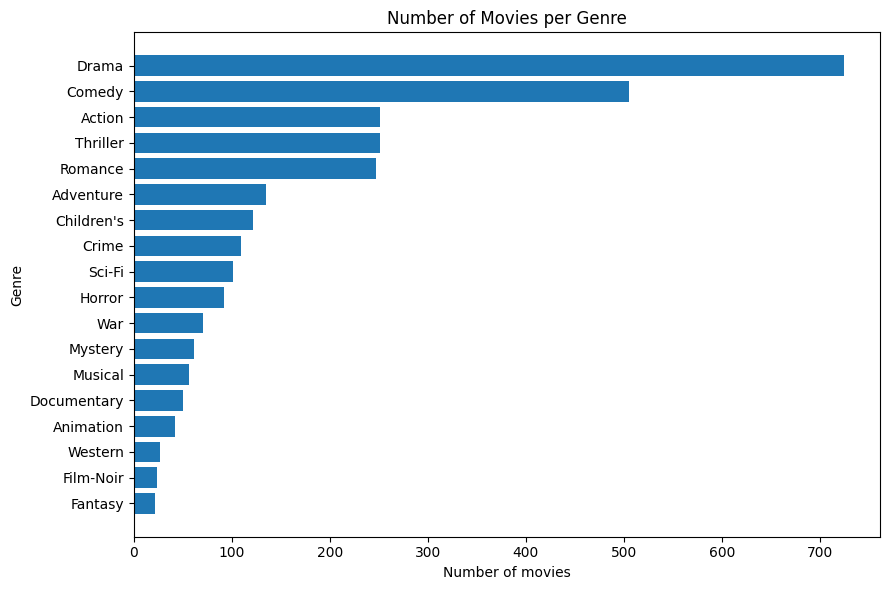

In [17]:
item_features = items.set_index("item_id")[genre_cols]

genre_counts = item_features.sum().sort_values()

plt.figure(figsize=(9, 6))
plt.barh(genre_counts.index, genre_counts.values)
plt.title("Number of Movies per Genre")
plt.xlabel("Number of movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

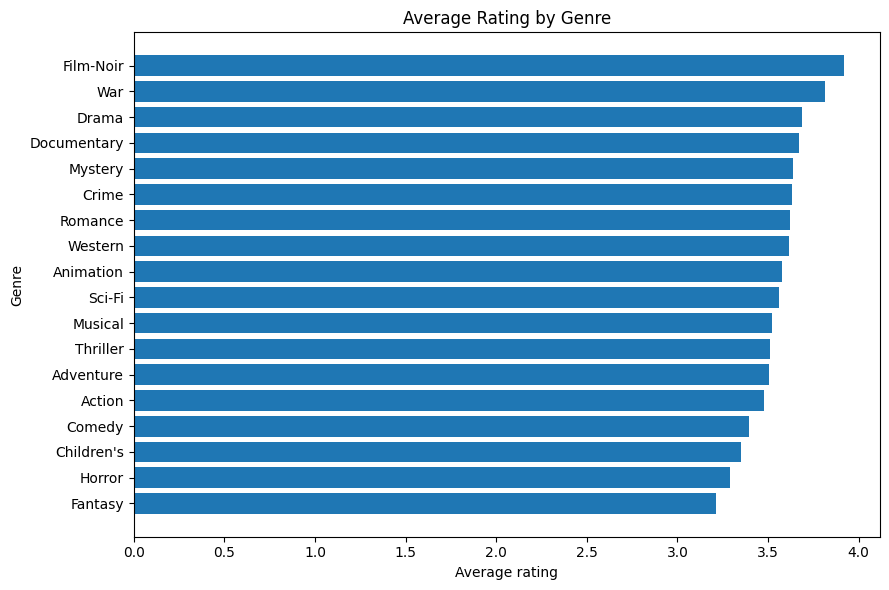

In [21]:
avg_rating_by_genre = (
    ratings_genres
    .groupby("genre")["rating"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9, 6))
plt.barh(avg_rating_by_genre.index, avg_rating_by_genre.values)
plt.title("Average Rating by Genre")
plt.xlabel("Average rating")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

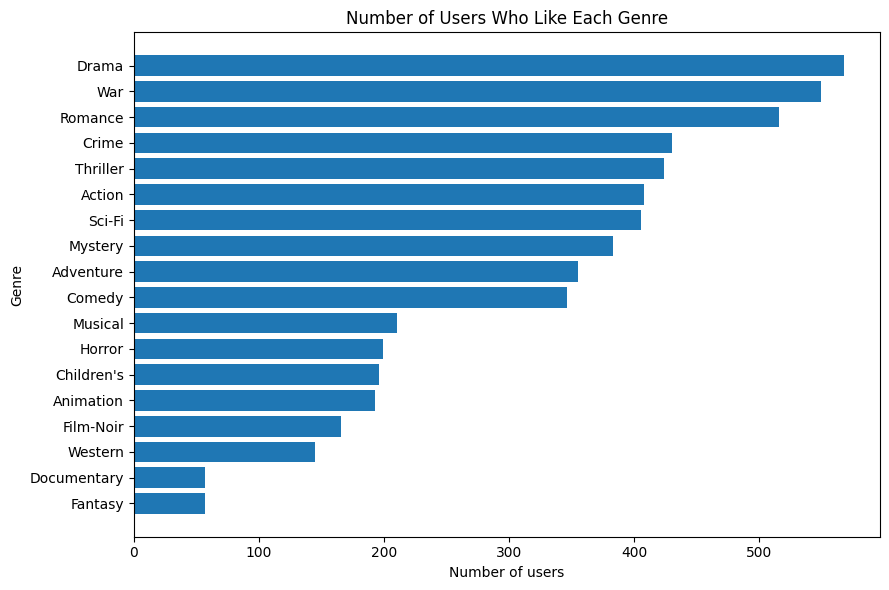

In [23]:
positive_threshold = 4
min_ratings_per_genre = 3
like_rate_threshold = 0.6

ratings_genres["liked"] = (
    ratings_genres["rating"] >= positive_threshold
).astype(int)

user_genre_stats = (
    ratings_genres
    .groupby(["user_id", "genre"])
    .agg(
        n_rated=("rating", "count"),
        mean_rating=("rating", "mean"),
        n_liked=("liked", "sum"),
        like_rate=("liked", "mean")
    )
    .reset_index()
)

user_genre_stats["likes_genre"] = (
    (user_genre_stats["n_rated"] >= min_ratings_per_genre) &
    (user_genre_stats["like_rate"] >= like_rate_threshold)
).astype(int)

user_genre_score = user_genre_stats.pivot(
    index="user_id",
    columns="genre",
    values="mean_rating"
).fillna(0)

user_genre_binary = user_genre_stats.pivot(
    index="user_id",
    columns="genre",
    values="likes_genre"
).fillna(0).astype(int)

# Ensure all genre columns exist and are ordered
user_genre_score = user_genre_score.reindex(columns=genre_cols, fill_value=0)
user_genre_binary = user_genre_binary.reindex(columns=genre_cols, fill_value=0)



users_per_liked_genre = user_genre_binary.sum().sort_values()

plt.figure(figsize=(9, 6))
plt.barh(users_per_liked_genre.index, users_per_liked_genre.values)
plt.title("Number of Users Who Like Each Genre")
plt.xlabel("Number of users")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

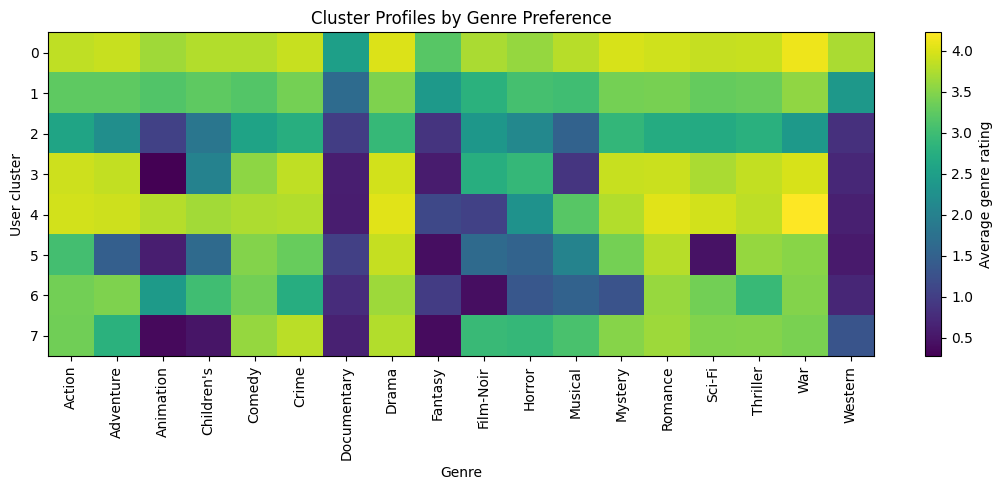

In [25]:
n_clusters = 8
plt.figure(figsize=(11, 5))
plt.imshow(cluster_profiles, aspect="auto")
plt.xticks(range(len(genre_cols)), genre_cols, rotation=90)
plt.yticks(range(n_clusters), cluster_profiles.index)
plt.title("Cluster Profiles by Genre Preference")
plt.xlabel("Genre")
plt.ylabel("User cluster")
plt.colorbar(label="Average genre rating")
plt.tight_layout()
plt.show()

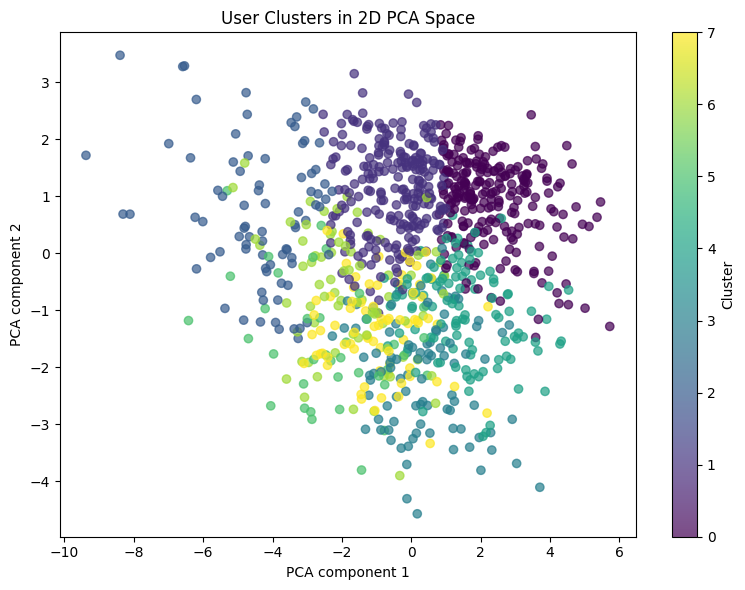

In [27]:
user_clusters = kmeans.fit_predict(X_user_scaled)

pca_2d = PCA(n_components=2, random_state=42)
user_2d = pca_2d.fit_transform(X_user_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(user_2d[:, 0], user_2d[:, 1], c=user_clusters, alpha=0.7)
plt.title("User Clusters in 2D PCA Space")
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()